# Assignment 5: ANOVA and Simple Linear Regression
Authored by Kristian M. P. Dashnaw (344849) & Katrine B. Aamand (344848) <br>
Based on assignment 5 description (https://rbrooksdk.github.io/STA1_26/assignments/assignment_05_anova_and_regression/)

## Table of Contents

1. **Part 1 — Composite strength across curing methods**
    - 1.1 Population, Unit, Response, Factor Levels, and Causal-Design Needs
    - 1.2 Group Summaries and Side-by-Side Boxplots
    - 1.3 One-Way ANOVA Hypotheses and Why Not Unadjusted Pairwise $t$-Tests
    - 1.4 Classical One-Way Model and ANOVA Table
2. **Part 2 — Diagnostics, post-hoc comparisons, and magnitude**
    - 2.1 Independence, Group Spreads, Residual Plots, and QQ-Plot
    - 2.2 Common-Variance Credibility and Welch's ANOVA Sensitivity Analysis
    - 2.3 $\eta^2$ as a Descriptive Fraction of Variation
    - 2.4 Tukey HSD: Simultaneous Intervals and Adjusted $p$-Values
    - 2.5 Recommendation in MPa
3. **Part 3 — Pump flow and energy use**
    - 3.1 Population, Unit, Variables, Predictor Range, and Scatterplot
    - 3.2 Intercept Model: $\hat\beta_0$, $\hat\beta_1$, Residual SD, $r$, and $R^2$
    - 3.3 Verifying $R^2=r^2$ and What Correlation and $R^2$ Measure
    - 3.4 Slope Test of $H_0:\beta_1=0$ and 95% Interval
4. **Part 4 — Regression diagnostics and prediction**
    - 4.1 Residual Plots and What They Cannot Establish
    - 4.2 Leverage, Cook's Distance, and the Most Influential Run
    - 4.3 Confidence and Prediction Intervals at $x_0=70$ L/min
    - 4.4 Extrapolation to 10 and 120 L/min
    - 4.5 Practical Conclusion
5. **Part 5 — AI-Use and Conclusion**
    - AI-Use Statement
    - Overall Conclusion

## Working Notes (DELETE BEFORE HANDIN)

**Overview (from the assignment description):**

> In this mini-project, you will analyse quantitative responses with two different predictors. ANOVA compares mean strength across categorical curing methods; simple linear regression models mean energy use against a quantitative flow rate. Both analyses require study-design reasoning, residual diagnostics, effect estimates, and uncertainty.

**Practical information (from the assignment description):**

> - **Group size:** 2–4 students
> - **Submission:** one executed Jupyter notebook in English
> - **Expected workload:** approximately 5–8 hours in total
> - **Statistical scope:** Sessions 9–10 and Brooks, Chapters 9–10
> - **Required method:** Python with statsmodels and SciPy where appropriate

**Preparation and data (from the assignment description):**

> Review Sessions and Tutorials [9](https://rbrooksdk.github.io/STA1_26/09_Analysis_of_Variance/) and [10](https://rbrooksdk.github.io/STA1_26/10_Simple_Linear_Regression/), together with [Brooks: Chapters 9–10](https://docs.google.com/viewer?url=https://raw.githubusercontent.com/RBrooksDK/STA_book_v1/main/main.pdf).
>
> Use:
>
> 1. [assignment05_composite_strength.csv](./data/assignment05_composite_strength.csv); and
> 2. [assignment05_pump_energy.csv](./data/assignment05_pump_energy.csv).
>
> Begin with the title, group members, table of contents, imports, and both files loaded from a local data folder.

**How to present the work (from the assignment description):**

> Use the fitted models to answer the stated engineering questions rather than copying complete software summaries without explanation. Every conclusion must include the effect in engineering units, uncertainty, diagnostic evidence, and design limitations.

**Working with AI (from the assignment description):**

> AI may help formulate models, use statsmodels, construct diagnostics, interpret output, and critique conclusions. You remain responsible for checking whether the code matches the question and whether assumptions are credible. Part 5 documents your AI use.

**Theory and code at the oral exam (from the assignment description):**

> The concepts below are the theory connected to this assignment. The oral examination will sample from this material; it is not expected to cover every item.
>
> Be prepared to use examples from this assignment to explain one-way ANOVA, between- and within-group variation, the $F$ statistic and ANOVA table, family-wise error, classical versus Welch ANOVA, Tukey HSD, $\eta^2$, the simple linear regression model, least squares, fitted values and residuals, slope and intercept, correlation, $R^2$, inference for the slope, diagnostics, leverage and influence, confidence versus prediction intervals, extrapolation, and the role of study design in causal interpretation.
>
> You need not memorise code, but you must understand every fitted model, output quantity, diagnostic, and engineering conclusion. AI use does not change this requirement.

In [23]:
#Imports:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

# Load the data files:
print("\nComposite_Strength.csv, first 5 rows:")
compositeStrengthData_unmodified = pd.read_csv('data/assignment05_composite_strength.csv', delimiter = ',')
display(compositeStrengthData_unmodified.head(5))

print("\n\nPump_Energy.csv, first 5 rows:")
pumpEnergyData_unmodified = pd.read_csv('data/assignment05_pump_energy.csv', delimiter = ',')
display(pumpEnergyData_unmodified.head(5))


Composite_Strength.csv, first 5 rows:


,specimen_id,curing_method,strength_mpa
0,1,ambient,53.09
1,2,ambient,48.91
2,3,ambient,55.11
3,4,ambient,54.53
4,5,ambient,57.05




Pump_Energy.csv, first 5 rows:


,run_id,flow_l_min,energy_kwh
0,1,22.70,18.110
1,2,22.93,13.534
2,3,23.42,15.300
3,4,24.35,17.677
4,5,25.13,18.420


<br><br><br>

---

<br>

## Part 1: Composite strength across curing methods

The file [assignment05_composite_strength.csv](./data/assignment05_composite_strength.csv) contains independent composite specimens cured by four methods. The response is `strength_mpa`; the factor is `curing_method`.

<br><br>
### 1.1 Identify the population, observational unit, response, factor, and factor levels. Explain what additional design information would be needed for a causal claim about curing method.

Authored by: Katrine
<br><br>

#### Step 1: Population, observational unit, response, factor and levels

|                    |                                                                                                                                              |
|:------------------:|:--------------------------------------------------------------------------------------------------------------------------------------------:|
|      Question      |              Does the mean strength differ between the four curing methods, and if so, which methods differ and by how much?                |
| Observational unit |                                                          A single composite specimen                                                         |
|    Populations     | Four populations, one per curing method: all composite specimens of this type cured with ambient, thermal, UV or hybrid curing,<br/>under the study conditions |
|     Parameters     |                 $\mu_{\text{ambient}}, \mu_{\text{thermal}}, \mu_{\text{uv}}, \mu_{\text{hybrid}}$, the population mean strengths in MPa                   |
|      Response      |                                  strength_mpa, the measured strength of each specimen (quantitative)                                         |
|       Factor       |                                  curing_method, the method used to cure the specimen (categorical)                                           |
|   Factor levels    |                                           ambient, thermal, uv and hybrid ($k = 4$ levels)                                                   |
|       Units        |                                                            MPa                                                                |

In [2]:
# Overview of the composite strength data: number of specimens and specimen_id range per curing method
print(compositeStrengthData_unmodified.groupby("curing_method")["specimen_id"].agg(["count", "min", "max"]))

               count  min  max
curing_method                 
ambient           24    1   24
hybrid            24   73   96
thermal           24   25   48
uv                24   49   72


#### Step 2: Design and causal claims

The sample contains $N = 96$ composite specimens, with $n = 24$ specimens for each of the four curing methods, so the design is balanced. According to the study description, the specimens are independent, meaning that each row is a separate specimen and the strength of one specimen does not affect another. Independence is assessed further in 2.1.

The data description does not state how the specimens were assigned to the curing methods, or how they were produced, stored and tested. We also notice that specimen_id runs in blocks: specimens 1–24 are ambient, 25–48 thermal, 49–72 uv and 73–96 hybrid. If specimen_id reflects the production or testing order, anything that changed over time, such as a new material batch or wear on the test machine, would affect a whole group at once and could look like a difference between curing methods. We cannot tell whether this is the case, since the IDs may have been assigned after the data were sorted.

Without this information, the ANOVA can only show an association between curing method and mean strength. A causal claim, i.e. that the curing method causes the difference in strength, would require the following additional design information:

| Design information | Alternative explanation it rules out |
|:---|:---|
| The specimens were randomly assigned to the curing methods | That the strongest specimens, e.g. from a better material batch, ended up together in one group |
| All specimens were stored under the same conditions and tested after the same time from curing | That differences in storage or time before testing, rather than the curing method, caused the difference |
| All specimens were tested on the same machine, in a random order, by an operator who did not know the curing method | That machine drift, differences between machines or operators, or the operator's expectations caused the difference |

<br><br>
### 1.2 Report group sample sizes, means, and sample standard deviations. Create side-by-side boxplots and describe between-group differences and within-group variation.

Authored by Katrine
<br><br>

#### Step 3: Descriptive summaries and plots

For each curing method, we compute the group size $n$, the sample mean $\bar{x}$ and the sample standard deviation $s$, and we compare the four groups with side-by-side boxplots. The dashed line shows the grand mean $\bar{x}_{\cdot\cdot}$ of all 96 specimens.

,n,mean,s
curing_method,,,
ambient,24,52.18,5.55
thermal,24,55.82,4.09
uv,24,55.42,3.44
hybrid,24,63.57,6.20


Grand mean = 56.75 MPa


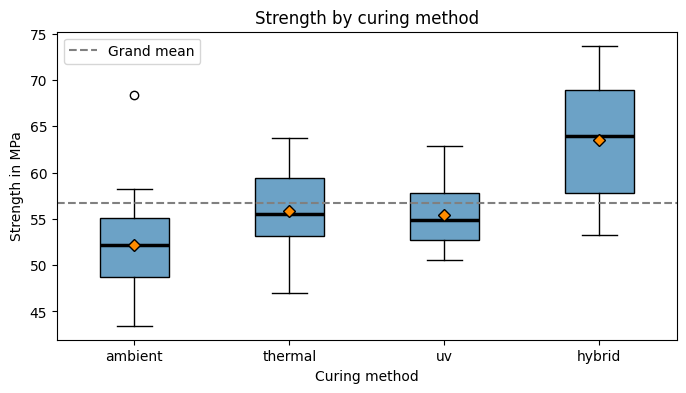

In [22]:
# Group summaries and side-by-side boxplots of strength for each curing method
composite = compositeStrengthData_unmodified
methods = ["ambient", "thermal", "uv", "hybrid"]

summary = composite.groupby("curing_method")["strength_mpa"].agg(n="count", mean="mean", s="std").reindex(methods)
display(summary.round(2))
print(f"Grand mean = {composite['strength_mpa'].mean():.2f} MPa")

groups = [composite.loc[composite["curing_method"] == m, "strength_mpa"] for m in methods]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(groups, showmeans=True, patch_artist=True, boxprops=dict(facecolor="#6CA2C6", edgecolor="black"), medianprops=dict(color="black", linewidth=2.5), meanprops=dict(marker="D", markerfacecolor="#FF8C00", markeredgecolor="black"))
ax.axhline(composite["strength_mpa"].mean(), color="gray", linestyle="--", linewidth=1.5, label="Grand mean")
ax.set_xticks(range(1, len(methods) + 1), methods)
ax.set(title="Strength by curing method", xlabel="Curing method", ylabel="Strength in MPa")
ax.legend()
plt.show()

##### Findings

Group summaries: All four curing methods have $n = 24$ specimens, so the design is balanced. Hybrid has the highest sample mean, $\bar{x} = 63.57$ MPa, followed by thermal ($\bar{x} = 55.82$ MPa) and uv ($\bar{x} = 55.42$ MPa), while ambient has the lowest, $\bar{x} = 52.18$ MPa.

Between-group differences: Hybrid lies clearly above the grand mean of 56.75 MPa, by about 6.8 MPa, and ambient lies about 4.6 MPa below it. Thermal and uv lie slightly below the grand mean and have almost the same mean, with a difference of only 0.4 MPa. The difference between the highest and the lowest group mean is 11.4 MPa.

Within-group variation: The spread differs between the groups. Hybrid varies the most, with $s = 6.20$ MPa, the tallest box and the longest whiskers, followed by ambient with $s = 5.55$ MPa. Uv varies the least, with $s = 3.44$ MPa and the shortest box. The largest standard deviation is therefore about 1.8 times the smallest. Whether this difference matters for the classical ANOVA is assessed in 2.2.

Overlap: The boxes of ambient, thermal and uv overlap considerably, so the variation within these groups is large compared with the differences between their means. The hybrid box lies higher than the others and only overlaps slightly with thermal and uv.

Outliers: Ambient has one high outlier at about 68 MPa, roughly 16 MPa above the ambient mean and above the hybrid median. It is not removed, but is examined further in the residual diagnostics in 2.1. The other groups show no outliers.

Center: In all four groups, the mean lies close to the median, which indicates no strong skew within the groups. In ambient, the high outlier and the long lower whisker pull in opposite directions, so the mean and the median are almost identical.

<br><br>
### 1.3 State the one-way ANOVA hypotheses. Explain why a collection of unadjusted pairwise $t$-tests is a poor default.

Authored by Katrine
<br><br>

#### Step 5: Hypotheses
<br><br>

##### Hypotheses
Let $\mu_{\text{ambient}}$, $\mu_{\text{thermal}}$, $\mu_{\text{uv}}$ and $\mu_{\text{hybrid}}$ denote the population mean strengths, in MPa, for the four curing methods.

$H_0: \mu_{\text{ambient}} = \mu_{\text{thermal}} = \mu_{\text{uv}} = \mu_{\text{hybrid}}$ (all four curing methods have the same population mean strength)

$H_1:$ not all four population means are equal (at least one curing method has a different population mean strength)

$H_1$ does not state that all four means differ from each other. It is already true if, for example, three methods have the same mean and only one differs. The one-way ANOVA $F$ test is therefore an omnibus test: it tells us whether the means differ, but not which ones. We use $\alpha = 0.05$.

<br><br>
##### Why not unadjusted pairwise $t$-tests
With $k = 4$ curing methods there are $4(4-1)/2 = 6$ pairs. If each pair were compared with its own unadjusted $t$-test at $\alpha = 0.05$, each test would have a 5% risk of a false alarm when there is no real difference. With six tests there are more chances of a false alarm, so the family-wise error rate, the probability of at least one type I error across all six comparisons, becomes larger than 5%. The stated $\alpha = 0.05$ would then no longer describe the actual risk. The exact probability depends on how the tests are related, since the pairs share groups, but it is clearly larger than 5%.

Instead, we first answer the global question with one $F$ test. If it is significant and we need to know which methods differ, we use Tukey's method in 2.4, which controls the family-wise error rate across all pairwise comparisons.

<br><br>
### 1.4 Fit the classical one-way model and produce an ANOVA table. Report sums of squares, degrees of freedom, mean squares, $F$, and $p$, and explain what the $F$ ratio compares.

Authored by Katrine
<br><br>

#### Step 5 (continued): The classical one-way model and the ANOVA table

The classical one-way model describes each strength measurement as its group's population mean plus a random error,

$$X_{ij} = \mu_i + \varepsilon_{ij}, \qquad \varepsilon_{ij} \sim N(0, \sigma^2),$$

where $i$ is the curing method and $j$ is the specimen within that method.
<br><br>
The errors are assumed to be independent and normal with the same variance $\sigma^2$ in all four groups. Whether these assumptions are credible is assessed in Part 2.

In [24]:
# Classical one-way ANOVA table for strength by curing method
anova_model = ols("strength_mpa ~ C(curing_method)", data=composite).fit()
anova_table = anova_lm(anova_model, typ=1)
display(anova_table.round(4))

# Total row and check of the sum-of-squares identity
ss_total = ((composite["strength_mpa"] - composite["strength_mpa"].mean()) ** 2).sum()
print(f"SS_total = {ss_total:.2f}, SS_between + SS_within = {anova_table['sum_sq'].sum():.2f}, df_total = {anova_table['df'].sum():.0f}")

# F and p computed from the mean squares
ms_between, ms_within = anova_table["mean_sq"]
df_between, df_within = anova_table["df"]
F_obs = ms_between / ms_within
p_value = f.sf(F_obs, df_between, df_within)
print(f"F = {ms_between:.2f} / {ms_within:.2f} = {F_obs:.2f}, df = ({df_between:.0f}, {df_within:.0f}), p = {p_value:.2e}")

,df,sum_sq,mean_sq,F,PR(>F)
C(curing_method),3.0,1682.0804,560.6935,22.9423,0.0
Residual,92.0,2248.4130,24.4393,NaN,NaN


SS_total = 3930.49, SS_between + SS_within = 3930.49, df_total = 95
F = 560.69 / 24.44 = 22.94, df = (3, 92), p = 3.55e-11


##### Findings
The sum-of-squares identity holds, $1682.08 + 2248.41 = 3930.49$, and the degrees of freedom add up, $3 + 92 = 95$.

What the $F$ ratio compares: The $F$ ratio compares the variation between the group means with the variation within the groups.
$$ F = MS_{between} / MS_{within} $$
$MS_{\text{within}} = 24.44$ MPa² estimates the common error variance $\sigma^2$, that is, the natural variation between specimens cured with the same method. Since the design is balanced, it equals the average of the four sample variances.
$MS_{\text{between}} = 560.69$ MPa² also estimates $\sigma^2$ if $H_0$ is true, but becomes larger when the population means differ. <br>
If $H_0$ were true, $F$ would therefore typically be close to 1. Here $F = 22.94$, so the variation between the curing methods is about 23 times larger than what the variation within the groups alone would lead us to expect.

Interpretation of the $p$-value: If $H_0$ is true and the model assumptions hold, then in repeated samples of 24 specimens per curing method, an $F$ statistic at least as large as 22.94 would occur with a probability of about $3.55 \times 10^{-11}$. Only the upper tail is used, because evidence against equal means appears when $MS_{\text{between}}$ is large compared with $MS_{\text{within}}$. The $p$-value is not the probability that $H_0$ is true.

Decision: Since $p = 3.55 \times 10^{-11} \leq \alpha = 0.05$, we reject $H_0$.

Conclusion: The data provide strong evidence that the population mean strengths are not all equal across the four curing methods. The $F$ test does not tell us which methods differ or by how much; this is examined with Tukey's method in 2.4. Nor does it show that the curing method causes the differences, since the design information described in 1.1 is missing. The conclusion also relies on the assumptions of the classical model, in particular a common variance, which is assessed in 2.1 and 2.2.

<br><br><br>

---

<br>

## Part 2: Diagnostics, post-hoc comparisons, and magnitude

Continue with the composite-strength study.

<br><br>
### 2.1 Diagnose independence from the study description and inspect within-group errors using group spreads, residual-versus-fitted, and a QQ-plot of residuals. Explain why the pooled raw response is not the correct normality diagnostic.

In [6]:
# TODO: Katrine

<br><br>
### 2.2 Decide whether the classical common-variance model is credible. Also run Welch's one-way ANOVA as a sensitivity analysis and explain why it is not paired automatically with ordinary Tukey HSD.

In [7]:
# TODO: Katrine

<br><br>
### 2.3 Calculate $\eta^2=SS_{\text{between}}/SS_{\text{total}}$ and interpret it as a descriptive fraction of observed squared variation, not causation.

In [8]:
# TODO: Katrine

<br><br>
### 2.4 If the classical omnibus test is relevant and significant, perform Tukey HSD. Report simultaneous pairwise intervals and adjusted $p$-values and identify which curing methods are distinguishable. Do not treat a non-significant pair as proof of equal means.

In [9]:
# TODO: Katrine

<br><br>
### 2.5 Write a recommendation in MPa that distinguishes the global question, specific pairwise differences, practical importance, and design limitations.

In [10]:
# TODO: Katrine

<br><br><br>

---

<br>

## Part 3: Pump flow and energy use

The file [assignment05_pump_energy.csv](./data/assignment05_pump_energy.csv) contains independent benchmark runs over an observed flow-rate range. Let energy use be $Y$ and flow rate be $x$, with the statistical model

$$
Y=\beta_0+\beta_1x+\varepsilon.
$$

Authored by: Kristian

Since this is a quantitative analysis (i.e. flow rate vs energy use, where both of these are quantitative data), this study becomes a simple linear regression problem, where we aim to describe systematic change in the conditional mean of $Y$.

Therefore, we will use the 8-step statistical regression workflow described in the Course Book (chapter 10.7, p. 154)

1. State the target population, observational unit, quantitative response, predictor, and intended operating range.
2. Explain how observations were sampled or experimental settings assigned, including run order, repeated units, and possible confounding.
3. Inspect the scatterplot for direction, linearity, unusual observations, clusters, and gaps in the predictor range.
4. Fit the least-squares line and interpret slope and intercept with units, without assigning meaning to an implausible intercept.
5. Examine residual-versus-fitted, residual-versus-order, and QQ-plots, together with leverage and influence diagnostics.
6. Report the slope estimate, confidence interval, test statistic, p-value, residual standard deviation, and $R^2$.
7. When prediction is required, distinguish a confidence interval for the mean response from a prediction interval for a new observation and avoid unsupported extrapolation.
8. Communicate practical importance, uncertainty, model limitations, and whether the design supports association or causation.



<br><br>
### 3.1 Identify the population, observational unit, response, predictor, and observed predictor range. Create a scatterplot and discuss whether a linear conditional-mean model is plausible before fitting it.
Authored by: Kristian

#### Step 1: State the target population, observational unit, quantitative response, predictor, and intended operating range.


In [11]:
# Kristian
# In order to determine the intended operating range, we need to inspect the actual data
print(pumpEnergyData_unmodified.head(3))
print("\n")
print(pumpEnergyData_unmodified[['flow_l_min', 'energy_kwh']].describe())
print("\n")
print("observed flow rate range:", pumpEnergyData_unmodified['flow_l_min'].min(), "l/min to ", pumpEnergyData_unmodified['flow_l_min'].max(), "l/min")

   run_id  flow_l_min  energy_kwh
0       1       22.70      18.110
1       2       22.93      13.534
2       3       23.42      15.300


       flow_l_min  energy_kwh
count   55.000000   55.000000
mean    57.910364   32.014127
std     23.793628   10.161864
min     22.700000   13.534000
25%     36.355000   23.522500
50%     59.960000   31.075000
75%     77.670000   40.817500
max     97.000000   49.793000


observed flow rate range: 22.7 l/min to  97.0 l/min


|                          |                                                                                                     |
|:------------------------:|:---------------------------------------------------------------------------------------------------:|
|    Observational Unit    |                                       A single benchmark run                                        |
|        Population        | Benchmark runs on this pump,<br/>under identical conditions as those in which the data was recorded |
|  Quantitative Response   |                   energy_kwh -> The energy consumption in kWh for each benchmark                    |
|  Quantitative Predictor  |                          flow_l_min -> The flow rate in liters per minute                           |
| Observed Predictor Range |                                Ranges from 22.7 l/min to 97.0 l/min.                                |
|          Units           |                          Flow rate in liters/minute and energy use in kWh.                          |

<br>

#### Step 2: Study design and assumptions.-> Explain how observations were sampled or experimental settings assigned, including run order, repeated units, and possible confounding.

A sample has been provided that includes 55 independently run benchmarks from a single pump, each benchmark details mean flow rate in liters/minute and the corresponding energy use (kWh).

Inspecting the data, we see that the data is already annotated with run_ids, such that the flow rate grows from its smallest value at run_id 1, and increases for each run_id. In effect, the data is already sorted ascending by the flow rate. We assume that the run_ids were added afterwards. The actual run order is therefore unknown, so we cannot rule out that warm-up, wear or drift changed together with the flow rate.

Based on the provided study description, we assume that "independent benchmarks" means that:
1. Each benchmark was run independently (i.e. no benchmarks were run concurrently), with benchmark run time being randomly selected (i.e. some benchmarks might start while pump is warming up, others might run while pump utilization is heavy, others while it's not, others while it's transitioning towards shut down, etc.).
2. Environmental influences (except flow rate) were kept stable between benchmarks.

Additionally, we assume that:
1. Each benchmark produced a mean flow rate (l/min) as well as an energy use - such that partial data was not filtered out of the sample (such as a flow rate of 0 l/min producing some energy use that the benchmark creator deemed to be irrelevant for this statistical analysis)
2. The observations were all made on the same pump.

<br>

#### Step 3: Inspect the scatterplot for direction, linearity, unusual observations, clusters, and gaps in the predictor range.
This inspection will be based on the inspection points described in the Course Book, Chapter 10.1, p. 143.

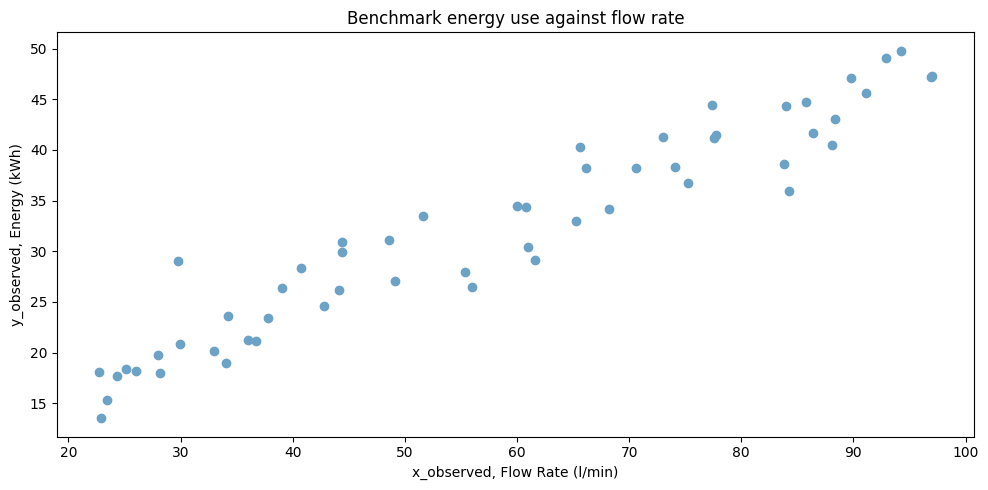

In [12]:
x = pumpEnergyData_unmodified["flow_l_min"]
y = pumpEnergyData_unmodified["energy_kwh"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(x, y, color="#6CA2C6")
ax.set_xlabel("x_observed, Flow Rate (l/min)")
ax.set_ylabel("y_observed, Energy (kWh)")
ax.set_title("Benchmark energy use against flow rate")
plt.tight_layout()
plt.show()

**Direction:** From the benchmark we see that the data points generally follow a linear increase in energy use as the flow rate increases

**Range of x** The observed range of x (flow rate) stretches from approx 22 l/min to approx 97 l/min. This matches what was computed earlier.

**Possible curvature:** There are no clear systematic curvatures in the observed data.

**Unusual observations:** At approx 30l/min there is an unusually high energy use of approx 30 kWh (about 10kWh above the rest of the surrounding observations). Same thing is seen at approx 84 l/min, although here the energy use was approx 7 kWh lower than surrounding.

**Gaps:** All observations are fairly evenly distributed inside the range of the flow rate.

**Regions with different variability:** The vertical spread looks roughly the same across the whole flow range.

**Clusters:** No completely separate groups can be observed.

<br>

Based on these observations a linear conditional-mean model is plausible for this dataset.



<br><br>
### 3.2 Fit an intercept model with statsmodels. Report and interpret $\hat\beta_0$, $\hat\beta_1$, residual standard deviation, Pearson correlation $r$, and $R^2$. Include units and discuss whether the intercept has a useful engineering interpretation.

In [13]:
# TODO: Kristian

<br><br>
### 3.3 Verify that $R^2=r^2$ for this simple intercept model. Explain what correlation and $R^2$ measure and what they do not establish.

In [14]:
# TODO: Kristian

<br><br>
### 3.4 Test $H_0:\beta_1=0$ against a two-sided alternative and report the slope estimate, standard error, 95% interval, $t$, degrees of freedom, and $p$-value. State the conclusion as an association, not automatically as causation.

In [15]:
# TODO: Kristian

<br><br><br>

---

<br>

## Part 4: Regression diagnostics and prediction

Continue with the pump study.

<br><br>
### 4.1 Create residual-versus-fitted, residual-versus-run-order, and normal QQ-plots. Discuss linearity, constant spread, unusual observations, normal-error approximation, and what the plots cannot establish about independence or sampling.

In [16]:
# TODO: Kristian

<br><br>
### 4.2 Calculate leverage and Cook's distance. Identify the most influential run, investigate it rather than deleting it automatically, and explain what operational information you would seek.

In [17]:
# TODO: Kristian

<br><br>
### 4.3 At $x_0=70$ L/min, report the fitted mean energy, a 95% confidence interval for mean energy, and a 95% prediction interval for one new run. Explain why the prediction interval is wider.

In [18]:
# TODO: Kristian

<br><br>
### 4.4 Explain why using this fitted line at 10 or 120 L/min would be extrapolation. State what evidence would be needed before extending the relationship outside the observed range.

In [19]:
# TODO: Kristian

<br><br>
### 4.5 Give a practical conclusion that includes slope in kWh per L/min, uncertainty, residual variation, $R^2$, prediction uncertainty, and study-design limitations.

In [20]:
# TODO: Kristian

<br><br><br>

---

<br>

## Part 5: AI-Use and Conclusion
### AI-use
> State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient.

#### In part 1 -  Clade Opus 5.5
`Assigned to: Katrine`
- AI was used as a tutor to explain one-way ANOVA (factor and levels, family-wise error, between- vs. within-group variation, the $F$ ratio and the ANOVA table), using examples from the book and interactive figures and simulations.
- AI provided the code for the group summaries, the boxplots and the ANOVA table, which I ran and checked.

##### What changed/got rejected:
- In 1.1, I first described equal group sizes as random assignment. After feedback, balance and random assignment were treated as two different things.
- In 1.4, I mixed up the between and residual rows in the output and first calculated $df_{\text{within}}$ as $96 - 3$. This was corrected to $N - k = 92$.

##### How we checked that the final work was correct:
- The sum-of-squares identity and the degrees of freedom were checked in code.
- $F$ was computed manually from the mean squares, and $p$ with `f.sf`, and both were compared with the `anova_lm` output.
- $MS_{\text{within}}$ was compared with my hand calculation of the average of the four sample variances.
- Methods and formulas were compared with Brooks, Chapter 9, and the session 9 material.
<br><br>

#### In part 2 -  Clade Opus 5.5
`Assigned to: Katrine`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

#### In part 3 - Clade Opus 5.5
`Assigned to: Kristian`
- AI was used to provide feedback on the manually drafted versions of task solutions.
- Assisted in resolving markdown properly syntax (latex)

##### What changed/got rejected:
- Typos got fixed, statements made more clear.

##### How we checked that the final work was correct:
- Compared to relevant sections from the course book (explanations and formulas from chapter 10), to ensure that AI based suggestions were rooted in the actual course literature.
<br><br>

#### In part 4 - [AI tool and model]
`Assigned to: Kristian`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

_____________

### Overall conclusion
> Write approximately 150–250 words comparing ANOVA and regression as methods for a quantitative response. Explain how the type of predictor determines the question, how residuals are used in both analyses, and why statistical modelling does not by itself prove causation.
>
> Only use Sessions 9–10. Do not use multiple regression or machine-learning workflows.

*TODO*

ANOVA (Parts 1–2) <br>
Mean composite strength differed among the four curing methods, $F(3, 92) = 22.94$, $p = 3.55 \times 10^{-11}$. Hybrid had the highest sample mean (63.57 MPa) and ambient the lowest (52.18 MPa), a difference of 11.4 MPa. *[Tukey results and $\eta^2$ are added after Part 2.]* Since the assignment of specimens to curing methods is not described, the result shows an association, not a causal effect of the curing method.

## Submission Checklist

- [ ] The ANOVA factor, response, units, and hypotheses are clear.
- [ ] Classical versus Welch ANOVA is justified from diagnostics.
- [ ] Tukey is used only with a compatible significant classical analysis.
- [ ] $\eta^2$ is not interpreted causally.
- [ ] Regression coefficients, $r$, and $R^2$ are interpreted correctly.
- [ ] Residual and influence diagnostics are included.
- [ ] Mean-response and prediction intervals are distinguished.
- [ ] Extrapolation and causal claims are limited.
- [ ] Part 5 contains AI-use and conclusion.
- [ ] All code is executed and output is visible.